# Extrachromosomal circular DNA formation follows a 10.5-bp periodicity reflecting the minor groove orientation around nucleosomes

## Import libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
from pathlib import Path
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.ndimage import gaussian_filter1d
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks, stft, butter, filtfilt, get_window
import scipy.signal as signal
from scipy.fft import fft, fftfreq
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

In [3]:
from src.preprocessing import merge_bed_files, prepare_and_plot_dataset_sizes
from src.length_distribution import plot_length_distributions, analyze_kde_peaks
from src.STFT import plot_stft_distributions, plot_amplitudes_vs_samples
from src.dyads import analyze_circle_breakpoints, analyze_circle_breakpoint_enrichment

## Data

**Folder structure.** `data/` contains only inputs that cannot be generated by this notebook (read-only). Everything produced by the notebook is written to `results/`, so deleting `results/` and re-running the notebook from top to bottom regenerates all outputs.

```
data/
├── arabidopsis/ chicken/ human/ mice/ mice1L3KO/   # individual eccDNA datasets
└── reference/                                      # external reference files
results/
├── merged/                  # whole, microDNA, Circle-Seq, ATAC-seq
├── dataset_size/  
├── length_distributions/
├── STFT/
├── dyads/                   # dyad calls, genic regions, non-genic circles, permutations
└── circle_breakpoints/
```

In [4]:
# Inputs (read-only): individual datasets
base_dir = Path("data")
folders = ["arabidopsis", "chicken", "human", "mice", "mice1L3KO"]

# Outputs: aggregated datasets are generated, so they go to results/
merged_dir = Path("results/merged")

whole_dir = merged_dir / "whole"
microdna_dir = merged_dir / "microDNA"
circleseq_dir = merged_dir / "Circle-Seq"
atacseq_dir = merged_dir / "ATAC-seq"

for d in [whole_dir, microdna_dir, circleseq_dir, atacseq_dir]:
    d.mkdir(parents=True, exist_ok=True)

whole_file = whole_dir / "whole.bed"
microdna_file = microdna_dir / "microDNA.bed"
circleseq_file = circleseq_dir / "Circle-Seq.bed"
atacseq_file = atacseq_dir / "ATAC-seq.bed"

whole_files = []
microdna_files = []
circleseq_files = []
atacseq_files = []

for folder in folders:
    folder_path = base_dir / folder
    if not folder_path.exists():
        continue

    for bed_file in sorted(folder_path.rglob("*.bed")):
        whole_files.append(bed_file)

        if bed_file.name.endswith("MD.bed"):
            microdna_files.append(bed_file)
        elif bed_file.name.endswith("CS.bed"):
            circleseq_files.append(bed_file)
        elif bed_file.name.endswith("AS.bed"):
            atacseq_files.append(bed_file)

merge_bed_files(whole_files, whole_file)
merge_bed_files(microdna_files, microdna_file)
merge_bed_files(circleseq_files, circleseq_file)
merge_bed_files(atacseq_files, atacseq_file)

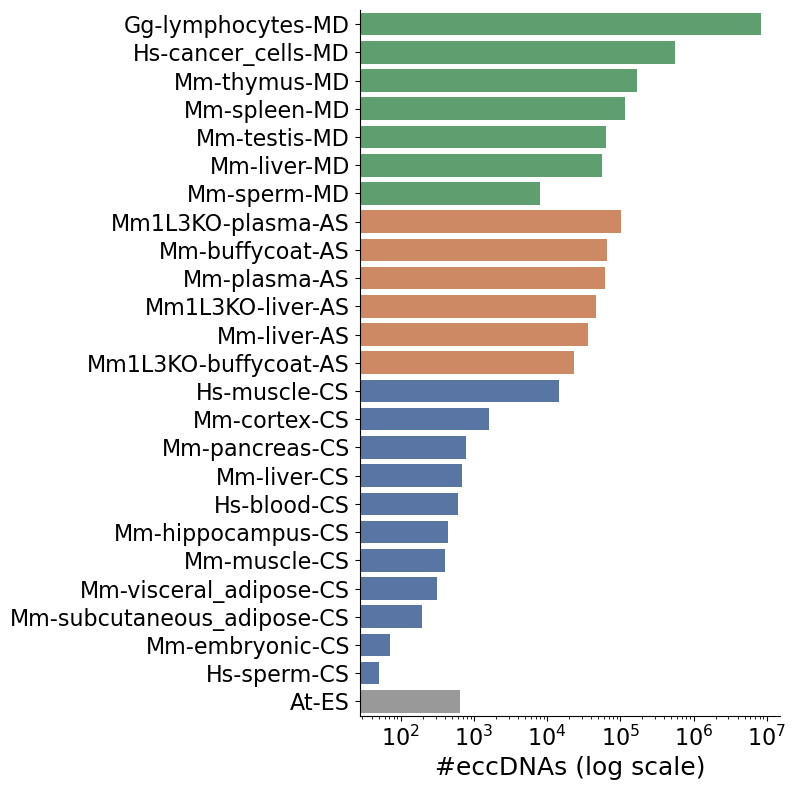

In [5]:
df, data_dict = prepare_and_plot_dataset_sizes(
    base_dir="data",
    merged_dir="results/merged",
    len_min=0,
    len_max=1000,
)

In [6]:
exclude_from_all = {
    "whole",
    "microDNA",
    "Circle-Seq",
    "ATAC-seq",
}

supplementary_order = [
    "whole",
    "microDNA",
    "Circle-Seq",
    "ATAC-seq",
    "Hs-muscle-CS",
    "Mm-plasma-AS",
]


all_datasets = [
    (
        key.removesuffix("_lengths"),
        data_dict[key]
    )
    for key in data_dict
    if key.endswith("_lengths")
]


supp_group = [
    (name, data_dict[f"{name}_lengths"])
    for name in supplementary_order
    if f"{name}_lengths" in data_dict
]

all_datasets = [
    item
    for item in all_datasets
    if item[0] not in exclude_from_all
]


all_datasets.sort(
    key=lambda x: len(x[1]),
    reverse=True
)


main_group = [
    item
    for item in all_datasets
    if item[0] not in supplementary_order
]

## eccDNA detection

### Length distribution

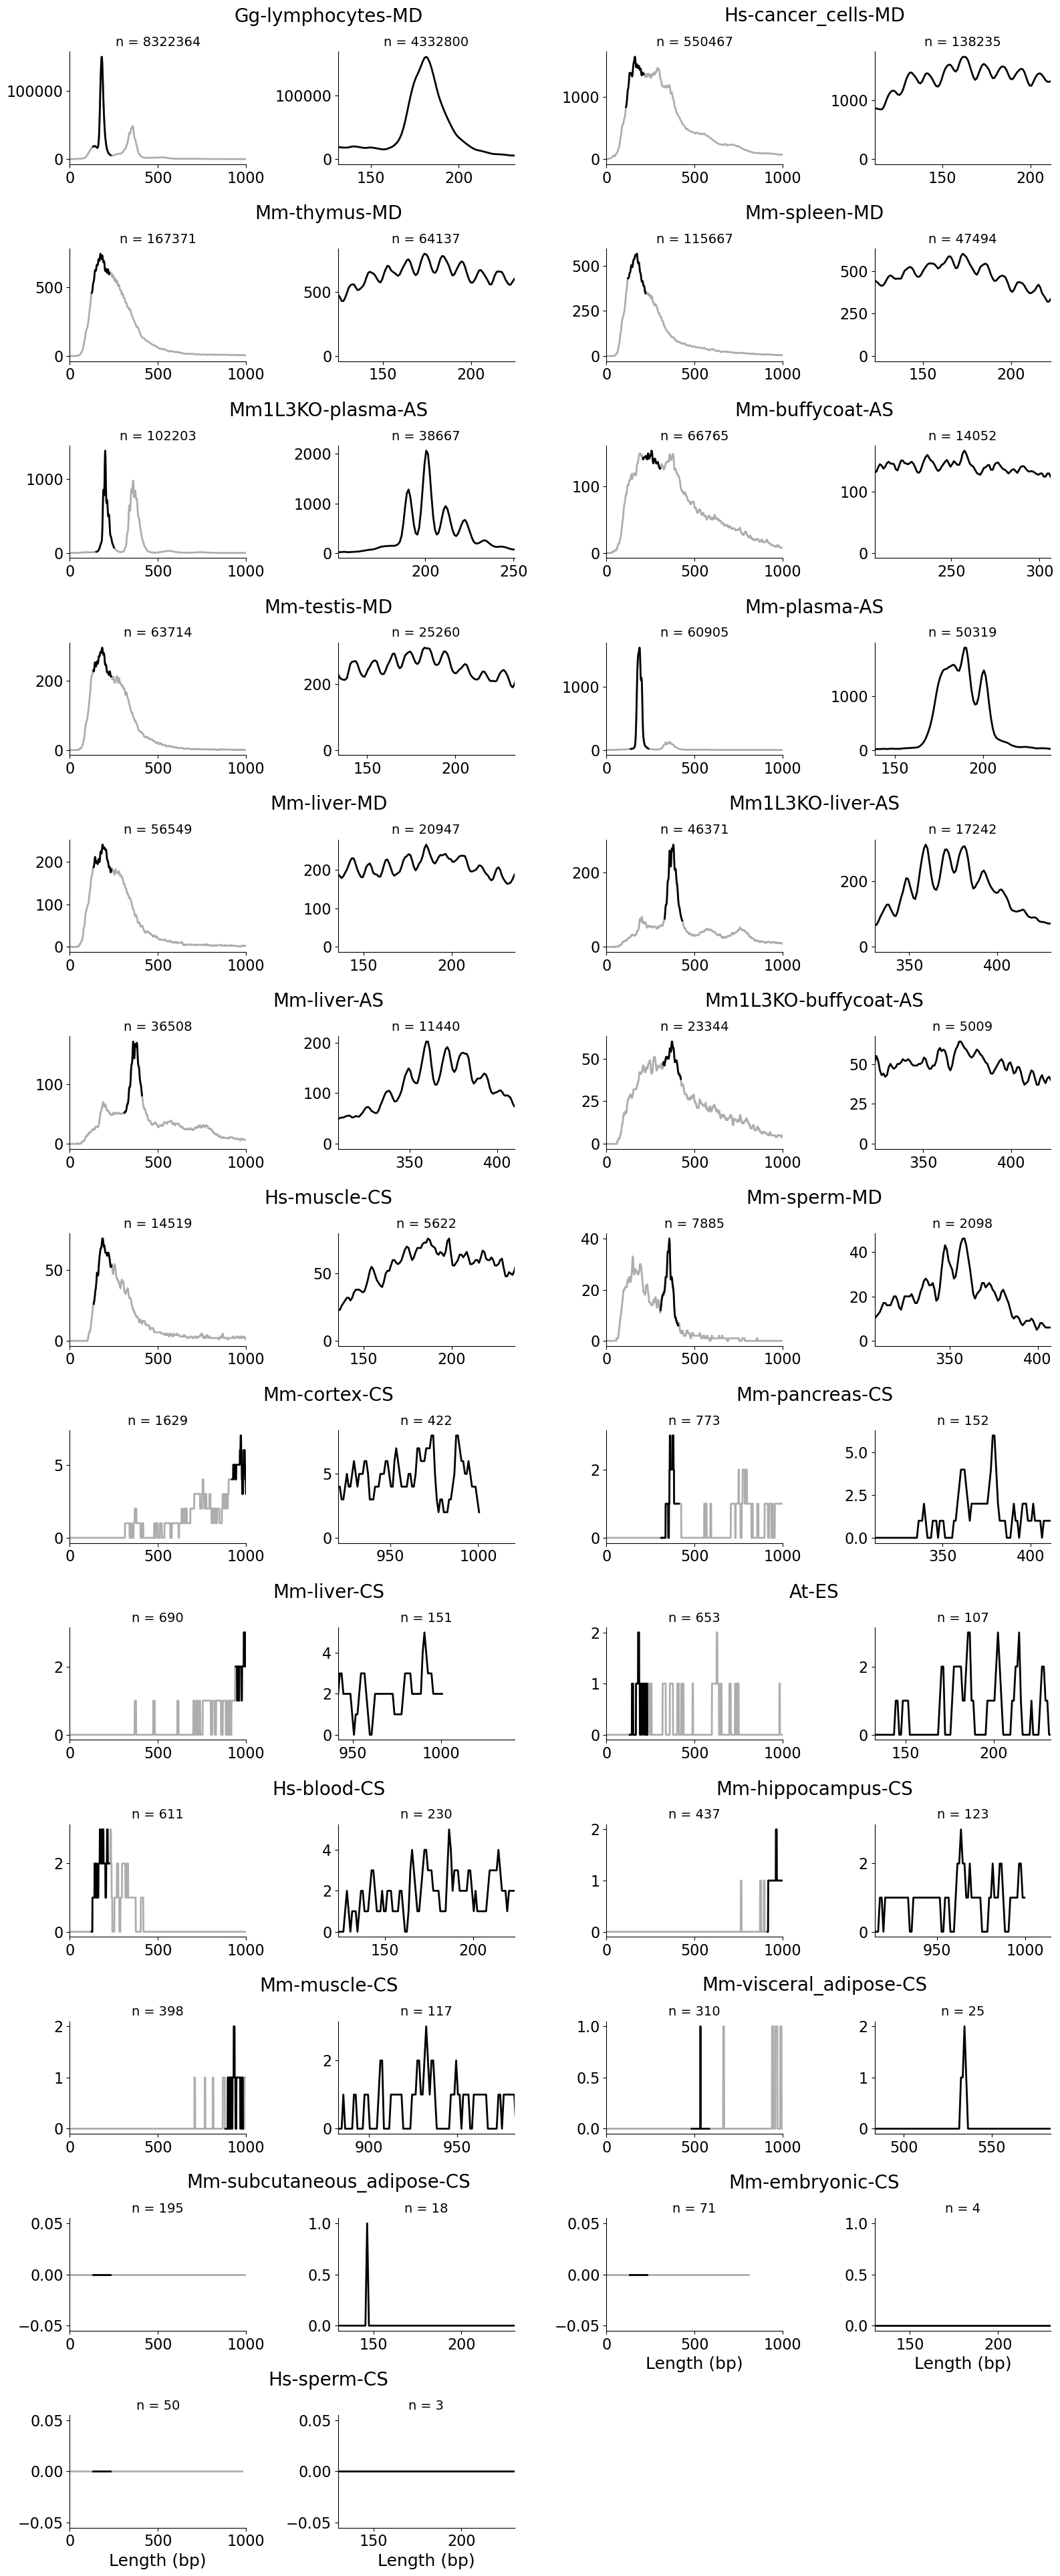

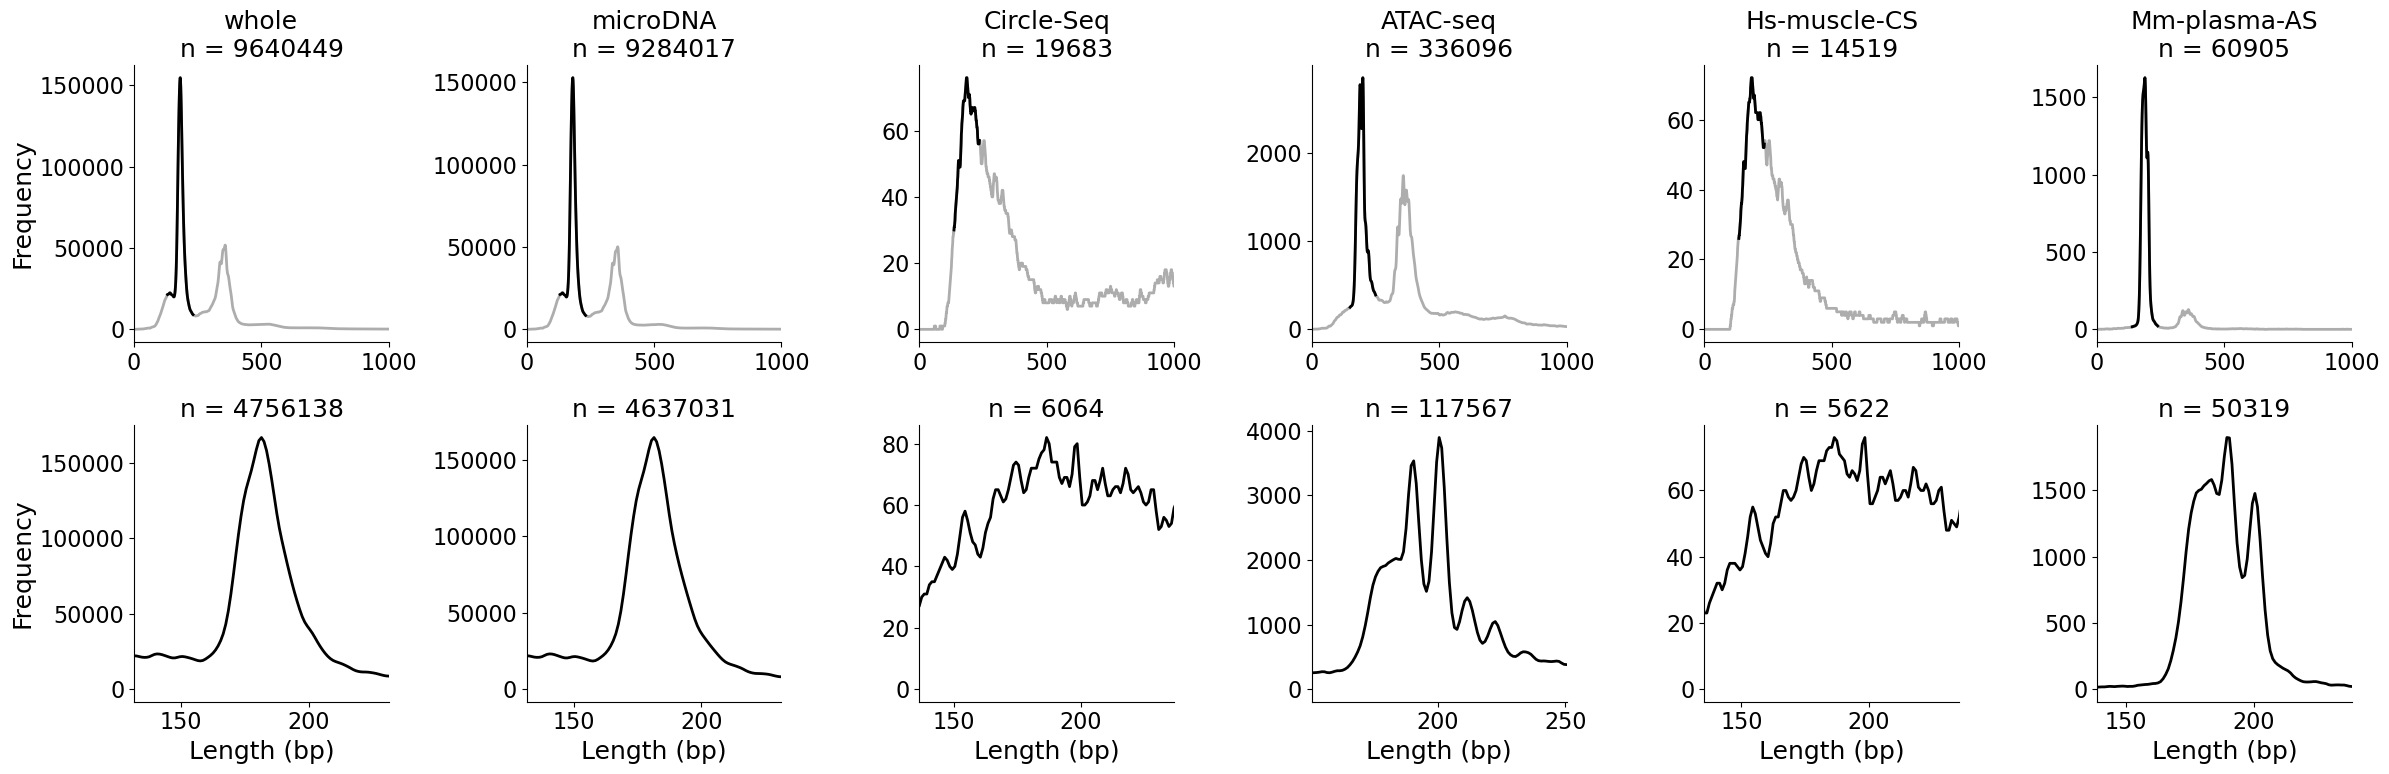

In [7]:
# ============================================================
# All datasets
# ============================================================

all_kde_results = plot_length_distributions(
    all_datasets,
    output_file="results/length_distributions/length_all.png",
    kde_output_file="results/length_distributions/kde_all_results.csv",
)


# ============================================================
# Supplementary datasets
# ============================================================

supp_kde_results = plot_length_distributions(
    supp_group,
    output_file="results/length_distributions/length_supp.png",
    kde_output_file="results/length_distributions/kde_supp_results.csv",
    verbose=True
)

## STFT Analysis 

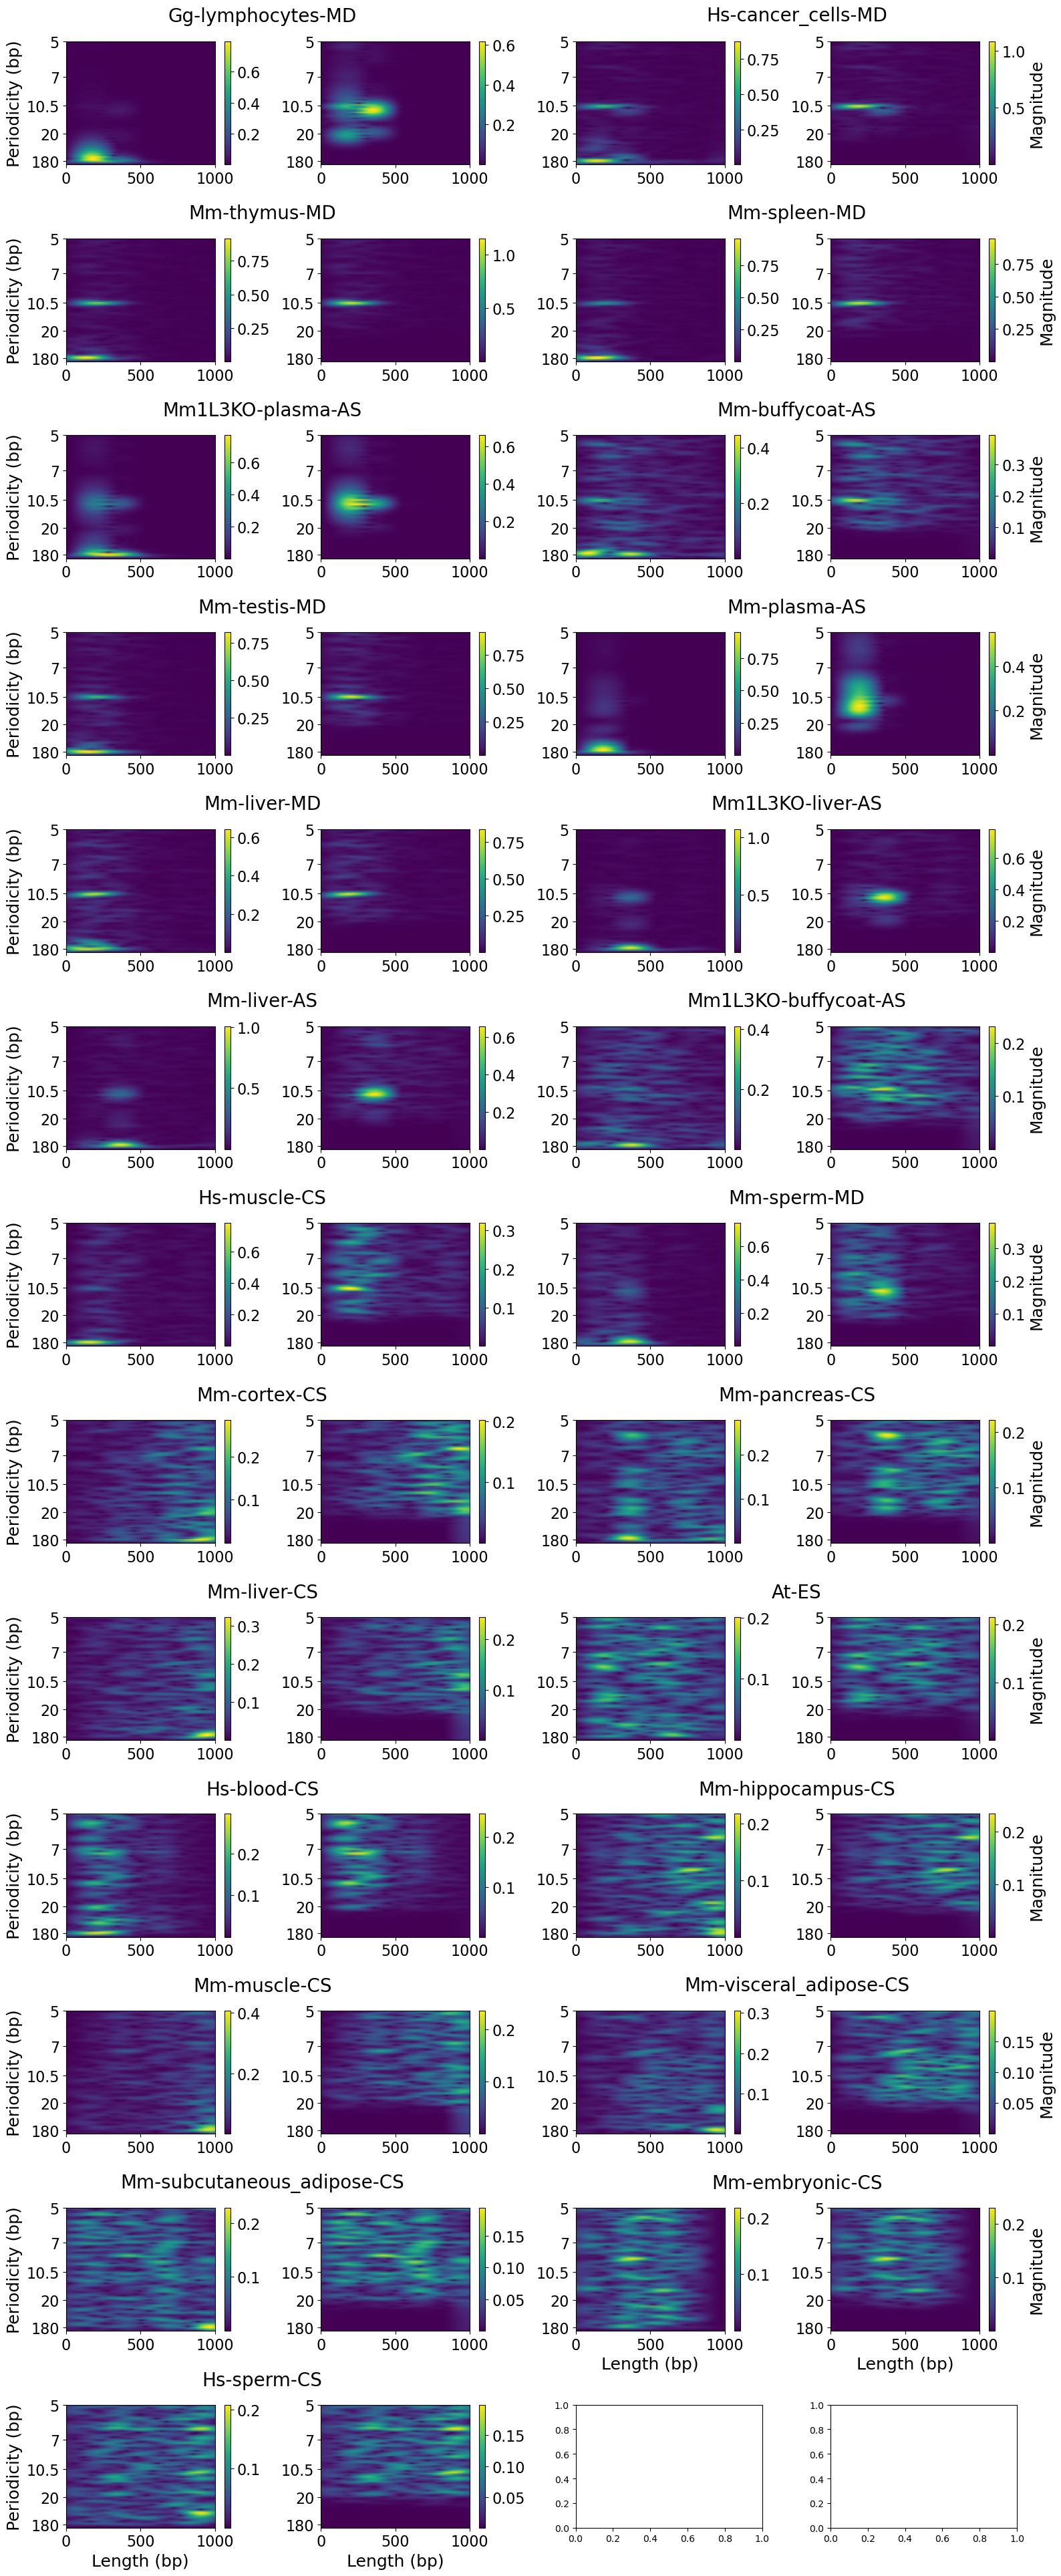

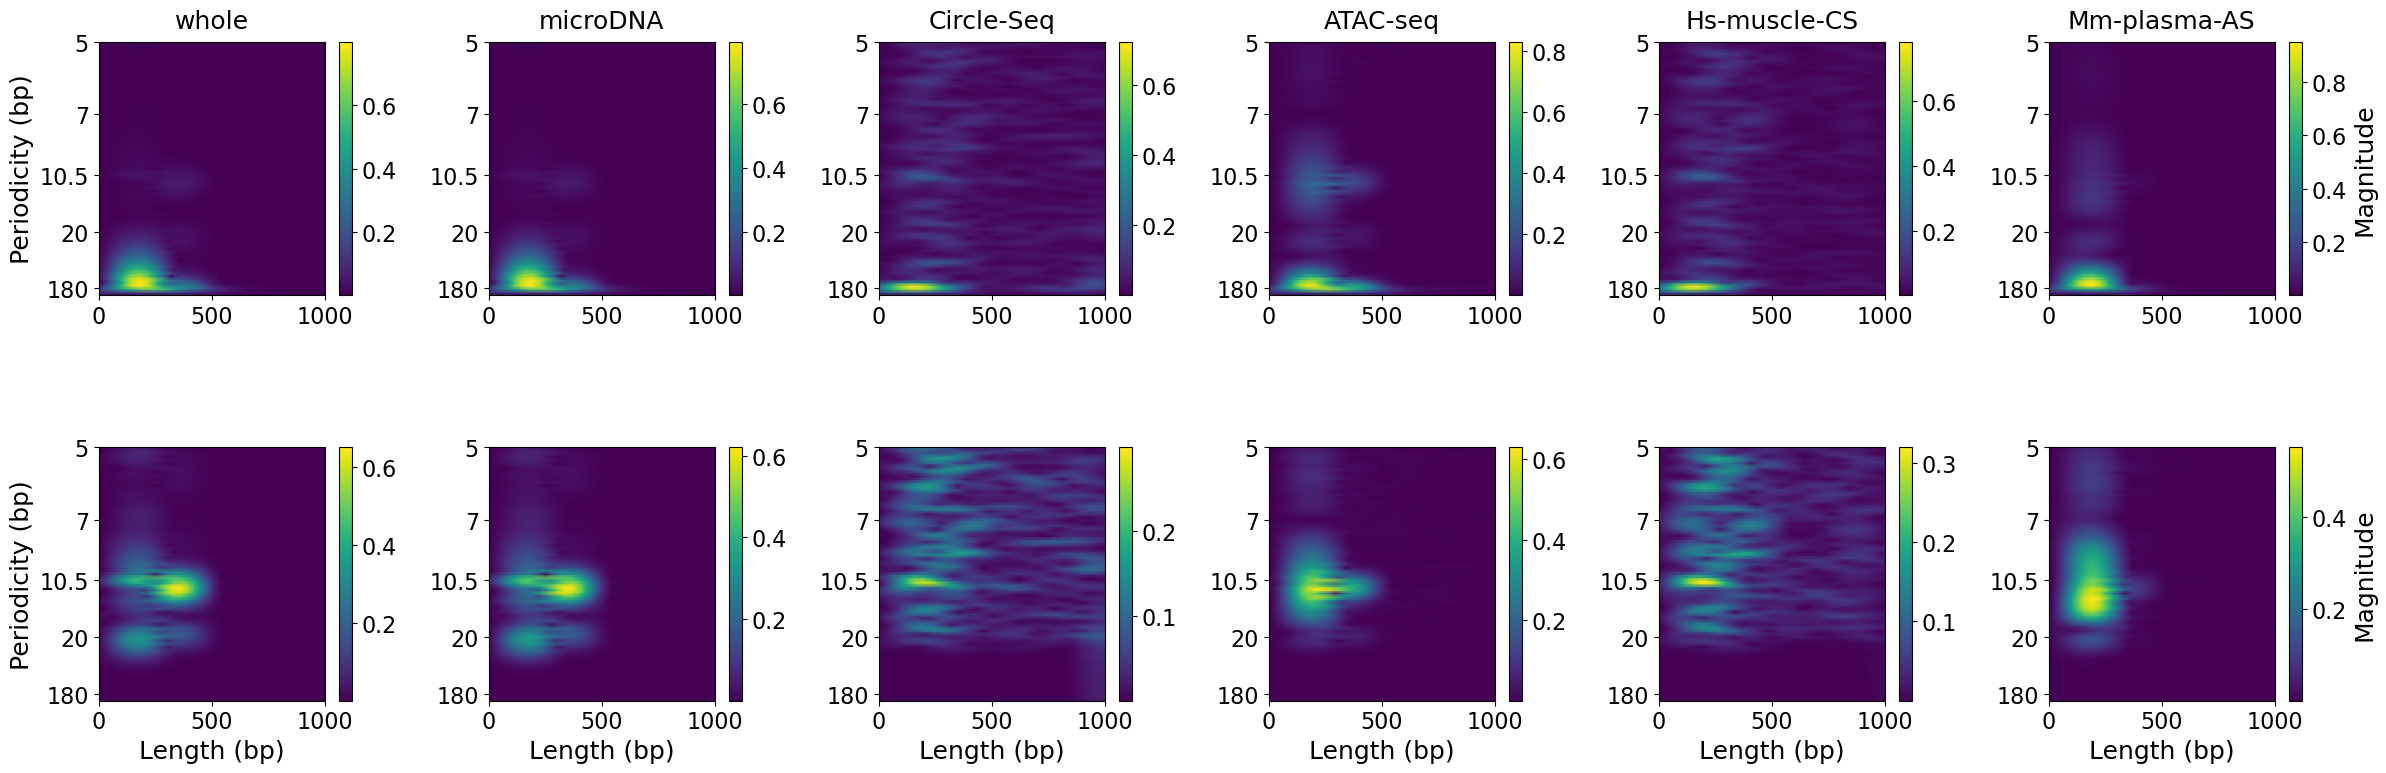

In [8]:
os.makedirs("results/STFT", exist_ok=True)

# ============================================================
# All datasets
# ============================================================

plot_stft_distributions(
    data_dict,
    [name for name, _ in all_datasets],
    "results/STFT/STFT_all.png"
)

# ============================================================
# Supplementary datasets
# ============================================================

plot_stft_distributions(
    data_dict,
    [name for name, _ in supp_group],
    "results/STFT/STFT_supp.png",
    verbose=True
)

## Testing sample size

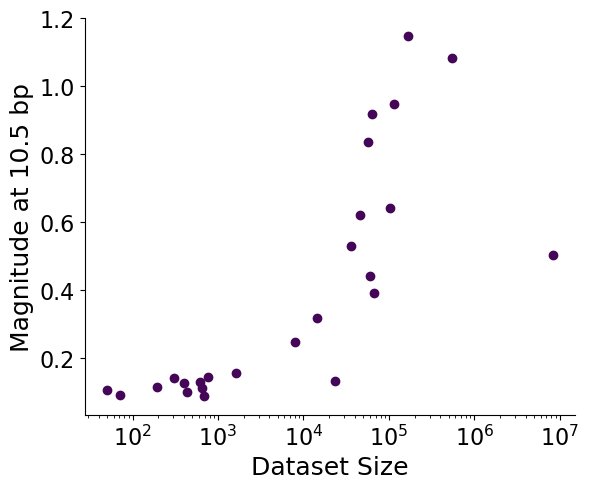

In [9]:
# Only individual datasets (aggregated groups are not independent)
plot_amplitudes_vs_samples(
    {f"{name}_lengths": lengths for name, lengths in all_datasets}
)

## Nucleosome and DNA rotation periodicity analysis

### Required input files

| File | Source |
|------|--------|
| `data/reference/GSE36979_mnase_mids_combined_147.wig.gz` | GEO accession GSE36979 (Gaffney et al. 2012) |
| `data/reference/hg18ToHg38.over.chain.gz` | UCSC liftOver chain (dyads, hg18 → hg38) |
| `data/reference/hg38.genome` | UCSC hg38 chromosome sizes |
| `data/reference/ENCFF356LFX.bed` | ENCODE hg38 blacklist |
| `results/dyads/merged_hg38.bed` | Human eccDNA in hg38 (provisional: to be generated in this notebook) |

External tools: `wigToBigWig`, `liftOver` (UCSC), `bedtools`.

### Step 1 — Call nucleosome dyads and lift over to hg38
Output: `results/dyads/gaffney_consensus_dyads_hg38.tsv`

In [10]:
# Step 1 — Rebuild the pooled human eccDNA coordinates in hg38 and check them
# against the deposited copy. results/dyads/merged_hg38.bed is a provided input of
# the Zenodo deposit (615,856 intervals, content md5 31e4f1f23a2438aa7e88db4ac3e29972
# after `sort -k1,1 -k2,2n`); the script re-derives it from the raw BED files and
# compares, without overwriting it, because its row order fixes the `shuffle -seed`
# draws of Step 3.
!bash src/make_merged_hg38.sh data/human data/reference/hg19ToHg38.over.chain.gz results/dyads

Chain OK: hg19 -> hg38
Reading liftover chains
Mapping coordinates
Reading liftover chains
Mapping coordinates
Reading liftover chains
Mapping coordinates
   696 results/dyads/liftover/Hs-blood-CS_hg38.bed
 20490 results/dyads/liftover/Hs-muscle-CS_hg38.bed
  1136 results/dyads/liftover/Hs-sperm-CS_hg38.bed
 22322 total
OK: results/dyads/merged_hg38.bed reproduced from the raw BED files
    content md5 31e4f1f23a2438aa7e88db4ac3e29972, 615856 intervals


In [11]:
!mkdir -p results/dyads
!bash src/run_gaffney_consensus_dyads_hg38.sh \
    data/reference/GSE36979_mnase_mids_combined_147.wig.gz \
    data/reference/hg18ToHg38.over.chain.gz \
    results/dyads/gaffney_consensus_dyads_hg38.tsv

chr1: 340,326 consensus dyads
chr10: 200,281 consensus dyads
chr11: 203,372 consensus dyads
chr12: 201,253 consensus dyads
chr13: 131,497 consensus dyads
chr14: 127,760 consensus dyads
chr15: 121,664 consensus dyads
chr16: 121,625 consensus dyads
chr17: 118,069 consensus dyads
chr18: 111,120 consensus dyads
chr19: 78,578 consensus dyads
chr2: 353,583 consensus dyads
chr20: 100,638 consensus dyads
chr21: 49,314 consensus dyads
chr22: 56,399 consensus dyads
chr3: 287,210 consensus dyads
chr4: 252,326 consensus dyads
chr5: 254,645 consensus dyads
chr6: 238,497 consensus dyads
chr7: 217,350 consensus dyads
chr8: 213,661 consensus dyads
chr9: 166,668 consensus dyads
chrX: 154,250 consensus dyads

Total: 4,100,086 consensus dyads
Saved to: gaffney_consensus_dyads_hg18.tsv
Reading liftover chains
Mapping coordinates
LiftOver complete.
Mapped BED:                 gaffney_consensus_dyads_hg38.bed
Unmapped BED:               gaffney_consensus_dyads_hg38.unmapped.bed
Mapped TSV (all columns):   g

In [12]:
# Step 2a — GENCODE v50 gene intervals -> results/dyads/hg38_genic_regions.bed
!bash src/getgenes.sh results/dyads

In [13]:
# Step 2b — Keep only non-genic circles
!bash src/non_genic.sh results/dyads

134551 results/dyads/non_genic_circles.bed


In [14]:
# Step 3 — 1000 seeded random permutations
!bash src/random.sh results/dyads data/reference 1000 8

1000


Consensus dyads after filtering: 3,158,492
Circles: 134,551
Breakpoint-dyad pairs: 258,620
Saved: results/circle_breakpoints/closest_consensus_dyads_to_circle_breakpoints.tsv


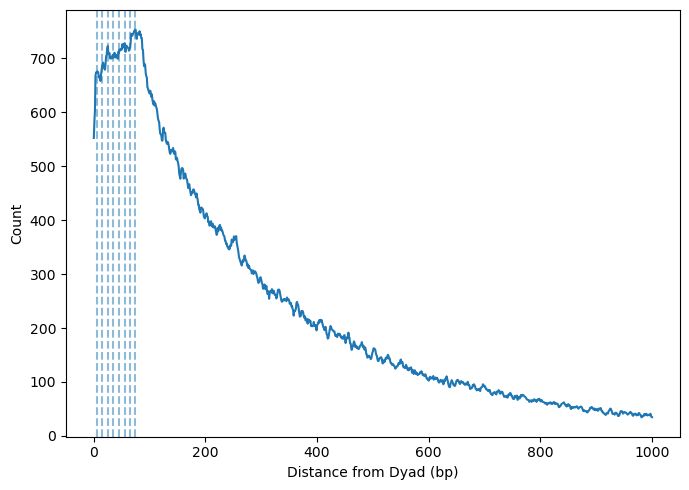

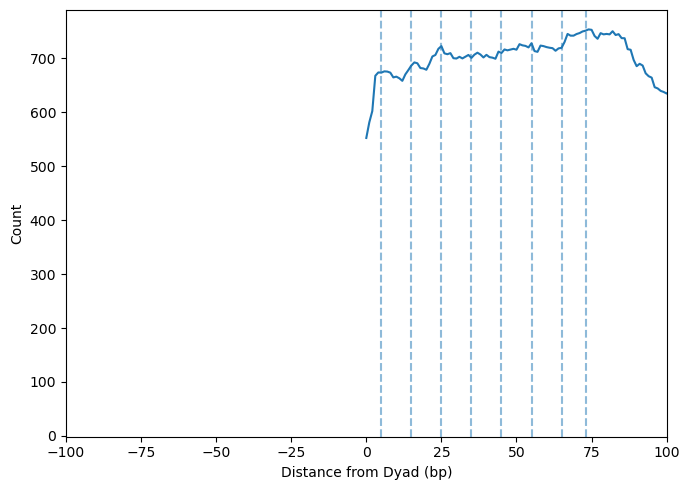

Plots saved with prefix: results/circle_breakpoints/distance_from_consensus_dyad_to_circle_breakpoints
Found 1000 permutation files.
[1/1000] Done: permutation_1.tsv
[2/1000] Done: permutation_10.tsv
[3/1000] Done: permutation_100.tsv
[4/1000] Done: permutation_1000.tsv
[5/1000] Done: permutation_101.tsv
[6/1000] Done: permutation_102.tsv
[7/1000] Done: permutation_103.tsv
[8/1000] Done: permutation_104.tsv
[9/1000] Done: permutation_105.tsv
[10/1000] Done: permutation_106.tsv
[11/1000] Done: permutation_107.tsv
[12/1000] Done: permutation_108.tsv
[13/1000] Done: permutation_109.tsv
[14/1000] Done: permutation_11.tsv
[15/1000] Done: permutation_110.tsv
[16/1000] Done: permutation_111.tsv
[17/1000] Done: permutation_112.tsv
[18/1000] Done: permutation_113.tsv
[19/1000] Done: permutation_114.tsv
[20/1000] Done: permutation_115.tsv
[21/1000] Done: permutation_116.tsv
[22/1000] Done: permutation_117.tsv
[23/1000] Done: permutation_118.tsv
[24/1000] Done: permutation_119.tsv
[25/1000] Done:

In [15]:
# Step 4 — Map each breakpoint to its closest strong dyad (observed + permutations)
breakpoint_results = analyze_circle_breakpoints(
    consensus_dyads_path="results/dyads/gaffney_consensus_dyads_hg38.tsv",
    circles_bed_path="results/dyads/non_genic_circles.bed",
    output_dir="results/circle_breakpoints",
    permutations_dir="results/dyads/random",
    n_jobs=8,
    positioning_score_threshold=0.5,
    run_permutations=True,
)

Plotting circle length nucleosomal phase...
Total circles before filtering: 134,551
Circles with length <= 200 bp: 34,435
Filtered length range: 9.0–200.0 bp
Periodicity: 10.50 bp
Phase range: 0.00–342.86°

10.5-bp phase distribution:
0.0–1.0°: 1448
1.0–2.0°: 0
2.0–3.0°: 0
3.0–4.0°: 0
4.0–5.0°: 0
5.0–6.0°: 0
6.0–7.0°: 0
7.0–8.0°: 0
8.0–9.0°: 0
9.0–10.0°: 0
10.0–11.0°: 0
11.0–12.0°: 0
12.0–13.0°: 0
13.0–14.0°: 0
14.0–15.0°: 0
15.0–16.0°: 0
16.0–17.0°: 0
17.0–18.0°: 1563
18.0–19.0°: 0
19.0–20.0°: 0
20.0–21.0°: 0
21.0–22.0°: 0
22.0–23.0°: 0
23.0–24.0°: 0
24.0–25.0°: 0
25.0–26.0°: 0
26.0–27.0°: 0
27.0–28.0°: 0
28.0–29.0°: 0
29.0–30.0°: 0
30.0–31.0°: 0
31.0–32.0°: 0
32.0–33.0°: 0
33.0–34.0°: 0
34.0–35.0°: 1494
35.0–36.0°: 0
36.0–37.0°: 0
37.0–38.0°: 0
38.0–39.0°: 0
39.0–40.0°: 0
40.0–41.0°: 0
41.0–42.0°: 0
42.0–43.0°: 0
43.0–44.0°: 0
44.0–45.0°: 0
45.0–46.0°: 0
46.0–47.0°: 0
47.0–48.0°: 0
48.0–49.0°: 0
49.0–50.0°: 0
50.0–51.0°: 0
51.0–52.0°: 1489
52.0–53.0°: 0
53.0–54.0°: 0
54.0–55.0°: 0
55

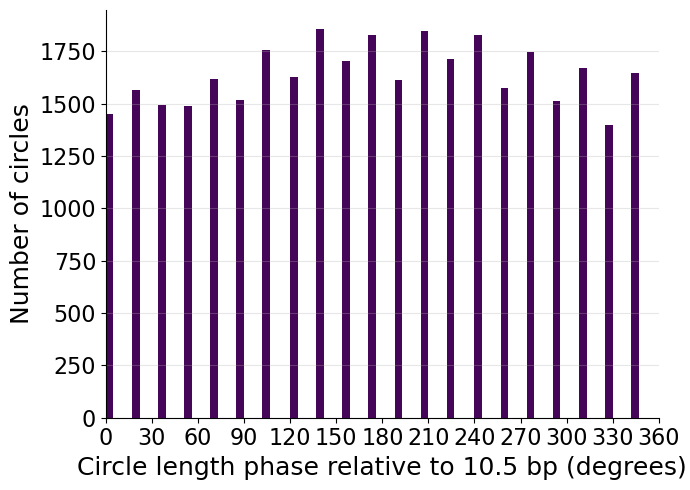

Loading observed data...
Observed breakpoint pairs: 51,774
Found 1000 permutation files.
Loading: permutation_1.tsv
Loading: permutation_10.tsv
Loading: permutation_100.tsv
Loading: permutation_1000.tsv
Loading: permutation_101.tsv
Loading: permutation_102.tsv
Loading: permutation_103.tsv
Loading: permutation_104.tsv
Loading: permutation_105.tsv
Loading: permutation_106.tsv
Loading: permutation_107.tsv
Loading: permutation_108.tsv
Loading: permutation_109.tsv
Loading: permutation_11.tsv
Loading: permutation_110.tsv
Loading: permutation_111.tsv
Loading: permutation_112.tsv
Loading: permutation_113.tsv
Loading: permutation_114.tsv
Loading: permutation_115.tsv
Loading: permutation_116.tsv
Loading: permutation_117.tsv
Loading: permutation_118.tsv
Loading: permutation_119.tsv
Loading: permutation_12.tsv
Loading: permutation_120.tsv
Loading: permutation_121.tsv
Loading: permutation_122.tsv
Loading: permutation_123.tsv
Loading: permutation_124.tsv
Loading: permutation_125.tsv
Loading: permuta

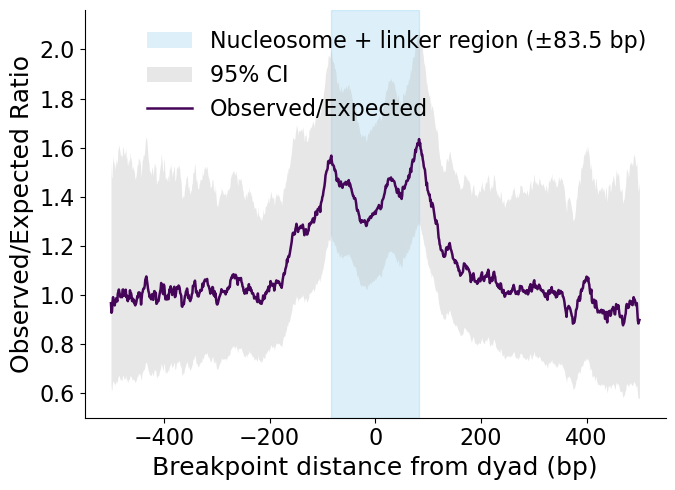

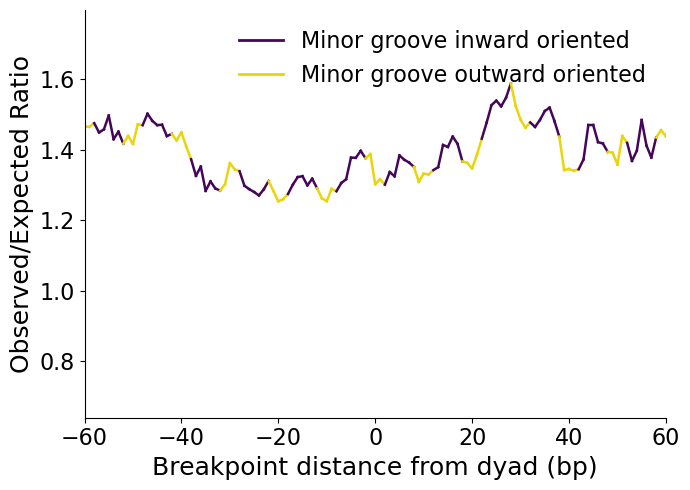

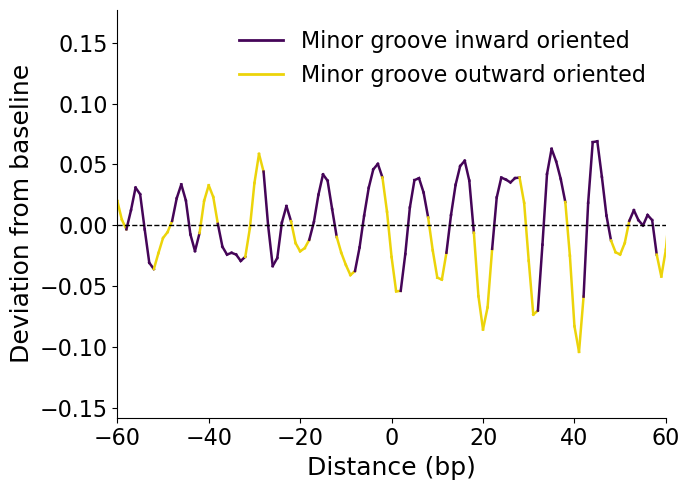

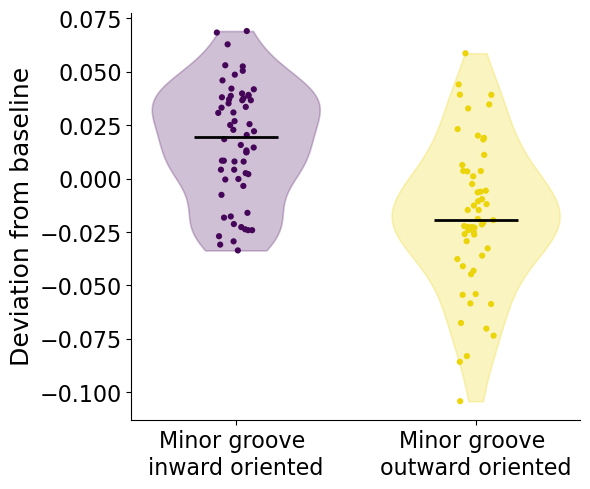


STATISTICAL COMPARISON: MINOR GROOVE ORIENTATION
Inward:  n = 60
Outward: n = 55
Inward median:  0.01942
Outward median: -0.01946
Inward mean:    0.01691
Outward mean:   -0.01789

--- Normality ---
Inward:  W = 0.9637, p = 7.1445e-02
Outward: W = 0.9878, p = 8.4864e-01

--- Group comparison ---
Test: Welch's t-test
Statistic = 5.9554
p-value = 3.7292e-08
Cohen's d = 1.1177
Statistics saved to: results/circle_breakpoints/enrichment/minor_groove_statistics.tsv


{'observed_distance': -500    20
 -499    16
 -498    12
 -497    20
 -496    13
         ..
  496    19
  497    14
  498    22
  499    21
  500    14
 Name: count, Length: 1001, dtype: int64,
 'expected_distances': {'permutation_1.tsv': -500    19
  -499    28
  -498    16
  -497    21
  -496    26
          ..
   496    17
   497    15
   498    19
   499    16
   500    21
  Name: count, Length: 1001, dtype: int64,
  'permutation_10.tsv': -500    16
  -499    16
  -498    16
  -497    22
  -496    19
          ..
   496    26
   497    20
   498    19
   499    17
   500    26
  Name: count, Length: 1001, dtype: int64,
  'permutation_100.tsv': -500    25
  -499    23
  -498    21
  -497    17
  -496    14
          ..
   496    19
   497    20
   498    16
   499    16
   500    20
  Name: count, Length: 1001, dtype: int64,
  'permutation_1000.tsv': -500    16
  -499    21
  -498    27
  -497    13
  -496    23
          ..
   496    20
   497    25
   498    14
   499    27
   50

In [16]:
# Step 5 — Observed/expected enrichment around dyads
analyze_circle_breakpoint_enrichment(
    observed_file="results/circle_breakpoints/closest_consensus_dyads_to_circle_breakpoints.tsv",
    permutations_dir="results/circle_breakpoints/random_closest_consensus_dyads",
    output_dir="results/circle_breakpoints/enrichment",
    circle_size=200,
    max_distance=500,
    smooth_window=21,
    circles_bed_path="results/dyads/non_genic_circles.bed"
)